# Unit Economics

- Compute average CLV per plan using average MRR and average customer lifespan.
- Compare CLV to CAC to determine the CLV:CAC ratio.

In [1]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import seaborn as sns

In [2]:
%load_ext sql
%config SqlMagic.autopandas = True
%sql duckdb://

Connecting to 'duckdb://'

In [3]:
%%sql
CREATE OR REPLACE TABLE subscriptions AS SELECT * FROM read_csv_auto('data/subscriptions.csv');

Running query in 'duckdb://'

,Success


In [4]:
%%sql
CREATE OR REPLACE TABLE monthly_revenue AS SELECT * FROM read_csv_auto('data/monthly_revenue.csv');

Running query in 'duckdb://'

,Success


In [5]:
%%sql unit_econ <<
WITH new AS (
SELECT plan, 
       DATE_TRUNC('month', signup_date) AS month,
       COUNT(*) AS new_customers,
  FROM subscriptions
GROUP BY plan, month),

churn AS (
SELECT plan,
       DATE_TRUNC('month', churn_date) AS month,
       COUNT(*) AS churned_customers
  FROM subscriptions
 WHERE churned = true
GROUP BY plan, month),

monthly AS (
SELECT COALESCE(n.plan, c.plan) AS plan,
       COALESCE(n.month, c.month) AS month,
       COALESCE(n.new_customers, 0) AS new_customers,
       COALESCE(c.churned_customers, 0) AS churned_customers
  FROM new n
FULL OUTER JOIN churn c USING(plan, month)
), 

roll AS (
SELECT plan, month, new_customers, churned_customers,
       SUM(new_customers - churned_customers) OVER (PARTITION BY plan ORDER BY month) AS total_active_customers
  FROM monthly
), 

base AS (
SELECT *,
       LAG(total_active_customers,1,0) OVER (PARTITION BY plan ORDER BY month) AS active_customers_last_month,
  FROM roll)
  


SELECT c.plan,
       ROUND(a.arpu, 2) AS arpu,
       ROUND(c.churn_rate, 3) AS churn_rate,
       ROUND(1.0 / c.churn_rate, 2) AS expected_customer_lifetime_months,
       ROUND(a.arpu * (1.0 / c.churn_rate), 2) AS expected_customer_lifetime_value
  FROM (SELECT plan,
               SUM(churned_customers) / SUM(active_customers_last_month) AS churn_rate
          FROM base
        GROUP BY plan) c 
  JOIN (SELECT plan, 
               AVG(monthly_revenue) AS arpu
          FROM subscriptions
        GROUP BY plan) a USING(plan)
ORDER BY CASE c.plan
         WHEN 'Starter' THEN 1
         WHEN 'Professional' THEN 2
         WHEN 'Business' THEN 3
         WHEN 'Enterprise' THEN 4
        END;
       

Running query in 'duckdb://'

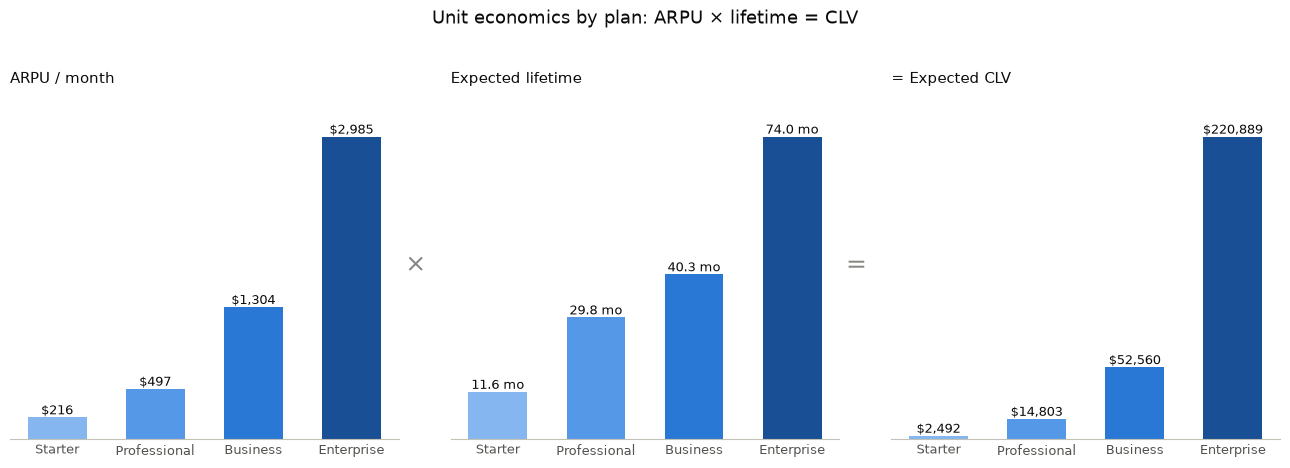

In [6]:
plan_order = ["Starter", "Professional", "Business", "Enterprise"]
plan_colors = {
    "Starter": "#86b6ef",
    "Professional": "#5598e7",
    "Business": "#2a78d6",
    "Enterprise": "#184f95",
}

df = unit_econ.set_index("plan").loc[plan_order].reset_index()

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))

panels = [
    (axes[0], "arpu", "${:,.0f}", "ARPU / month"),
    (axes[1], "expected_customer_lifetime_months", "{:,.1f} mo", "Expected lifetime"),
    (axes[2], "expected_customer_lifetime_value", "${:,.0f}", "= Expected CLV"),
]

for i, (ax, col, fmt, title) in enumerate(panels):
    bars = ax.bar(
        df["plan"],
        df[col],
        color=[plan_colors[p] for p in df["plan"]],
        width=0.6,
    )
    for bar, value in zip(bars, df[col]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            fmt.format(value),
            ha="center", va="bottom",
            fontsize=9, color="#0b0b0b",
        )
    ax.set_title(title, fontsize=11, color="#0b0b0b", loc="left")
    ax.set_ylabel("")
    ax.set_yticks([])
    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)
    ax.spines["bottom"].set_color("#c3c2b7")
    ax.tick_params(axis="x", length=0, labelcolor="#52514e", labelsize=9)
    ax.margins(y=0.15)

    if i > 0:
        ax.text(
            -0.09, 0.5, "×" if i == 1 else "=",
            transform=ax.transAxes, ha="center", va="center",
            fontsize=18, color="#898781",
        )

fig.suptitle("Unit economics by plan: ARPU × lifetime = CLV", fontsize=13, color="#0b0b0b", y=1.03)
plt.tight_layout()
plt.show()

## CLV vs. CAC

`customer_acquisition_cost` only exists in `monthly_revenue` at the whole-company, monthly level — there's no per-plan breakdown — so this piece is computed across all customers combined rather than per plan.

In [7]:
%%sql clv_cac <<
WITH new AS (
SELECT DATE_TRUNC('month', signup_date) AS month,
       COUNT(*) AS new_customers
  FROM subscriptions
GROUP BY month),

churn AS (
SELECT DATE_TRUNC('month', churn_date) AS month,
       COUNT(*) AS churned_customers
  FROM subscriptions
 WHERE churned = true
GROUP BY month),

monthly AS (
SELECT COALESCE(n.month, c.month) AS month,
       COALESCE(n.new_customers, 0) AS new_customers,
       COALESCE(c.churned_customers, 0) AS churned_customers
  FROM new n
FULL OUTER JOIN churn c USING(month)
),

roll AS (
SELECT month, new_customers, churned_customers,
       SUM(new_customers - churned_customers) OVER (ORDER BY month) AS total_active_customers
  FROM monthly
),

base AS (
SELECT *,
       LAG(total_active_customers,1,0) OVER (ORDER BY month) AS active_customers_last_month
  FROM roll)

SELECT ROUND(a.arpu, 2) AS arpu,
       ROUND(c.churn_rate, 4) AS churn_rate,
       ROUND(1.0 / c.churn_rate, 2) AS expected_customer_lifetime_months,
       ROUND(a.arpu * (1.0 / c.churn_rate), 2) AS expected_customer_lifetime_value,
       ROUND(cac.avg_cac, 2) AS cac,
       ROUND((a.arpu * (1.0 / c.churn_rate)) / cac.avg_cac, 2) AS clv_cac_ratio
  FROM (SELECT SUM(churned_customers) / SUM(active_customers_last_month) AS churn_rate FROM base) c
 CROSS JOIN (SELECT AVG(monthly_revenue) AS arpu FROM subscriptions) a
 CROSS JOIN (SELECT AVG(customer_acquisition_cost) AS avg_cac FROM monthly_revenue) cac;

Running query in 'duckdb://'

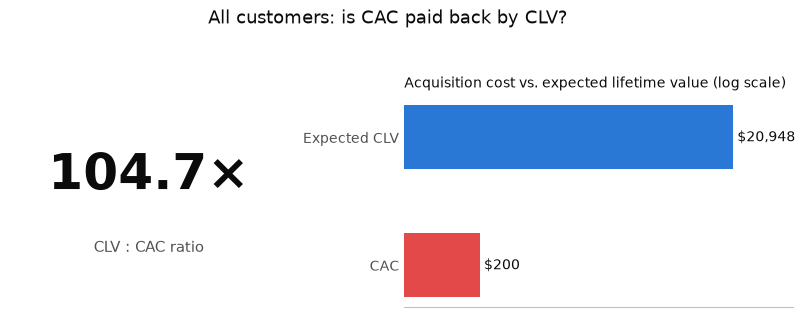

In [8]:
import matplotlib.gridspec as gridspec

row = clv_cac.iloc[0]
cac = row["cac"]
clv = row["expected_customer_lifetime_value"]
ratio = row["clv_cac_ratio"]

fig = plt.figure(figsize=(9, 3.2))
gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1.4], wspace=0.35, figure=fig)

ax_stat = fig.add_subplot(gs[0])
ax_stat.axis("off")
ax_stat.text(0.5, 0.62, f"{ratio:,.1f}×", ha="center", va="center",
             fontsize=36, color="#0b0b0b", fontweight="bold")
ax_stat.text(0.5, 0.28, "CLV : CAC ratio", ha="center", va="center",
             fontsize=11, color="#52514e")

ax_bar = fig.add_subplot(gs[1])
labels = ["CAC", "Expected CLV"]
values = [cac, clv]
colors = ["#e34948", "#2a78d6"]
bars = ax_bar.barh(labels, values, color=colors, height=0.5)
ax_bar.set_xscale("log")
for bar, value in zip(bars, values):
    ax_bar.text(bar.get_width() * 1.08, bar.get_y() + bar.get_height() / 2,
                f"${value:,.0f}", va="center", fontsize=10, color="#0b0b0b")
ax_bar.set_xlim(50, clv * 3)
ax_bar.set_title("Acquisition cost vs. expected lifetime value (log scale)",
                  fontsize=10, color="#0b0b0b", loc="left")
for spine in ["top", "right", "left"]:
    ax_bar.spines[spine].set_visible(False)
ax_bar.spines["bottom"].set_color("#c3c2b7")
ax_bar.xaxis.set_visible(False)
ax_bar.tick_params(axis="y", length=0, labelcolor="#52514e", labelsize=10)

fig.suptitle("All customers: is CAC paid back by CLV?", fontsize=13, color="#0b0b0b", y=1.05)
fig.subplots_adjust(left=0.08, right=0.95, top=0.78, bottom=0.12)
plt.show()

## CLV:CAC Trend Over Time (Monthly, trailing 3-month average)

`monthly_revenue` already has everything needed for a monthly CLV:CAC ratio — `avg_revenue_per_customer`, `monthly_churn_rate_pct`, and `customer_acquisition_cost` are all reported per month. Raw single-month values are noisy (early months have very few customers, so churn swings between 0% and 20%), so each input is smoothed with a trailing 3-month average before computing CLV and the ratio. Months where the smoothed churn rate is still 0 are excluded (undefined lifetime).

In [9]:
%%sql monthly_clv_cac <<
WITH ordered AS (
SELECT STRPTIME(month, '%Y-%m') AS month_date,
       avg_revenue_per_customer,
       monthly_churn_rate_pct,
       customer_acquisition_cost AS cac
  FROM monthly_revenue
),

smoothed AS (
SELECT month_date,
       AVG(avg_revenue_per_customer) OVER (ORDER BY month_date ROWS BETWEEN 2 PRECEDING AND CURRENT ROW) AS arpu_3mo,
       AVG(monthly_churn_rate_pct) OVER (ORDER BY month_date ROWS BETWEEN 2 PRECEDING AND CURRENT ROW) AS churn_rate_pct_3mo,
       AVG(cac) OVER (ORDER BY month_date ROWS BETWEEN 2 PRECEDING AND CURRENT ROW) AS cac_3mo
  FROM ordered
)

SELECT month_date,
       ROUND(arpu_3mo, 2) AS arpu_3mo,
       ROUND(churn_rate_pct_3mo, 3) AS churn_rate_pct_3mo,
       ROUND(cac_3mo, 2) AS cac_3mo,
       ROUND(arpu_3mo / (churn_rate_pct_3mo / 100.0), 2) AS clv_3mo,
       ROUND((arpu_3mo / (churn_rate_pct_3mo / 100.0)) / cac_3mo, 2) AS clv_cac_ratio_3mo
  FROM smoothed
 WHERE churn_rate_pct_3mo > 0
 ORDER BY month_date;

Running query in 'duckdb://'

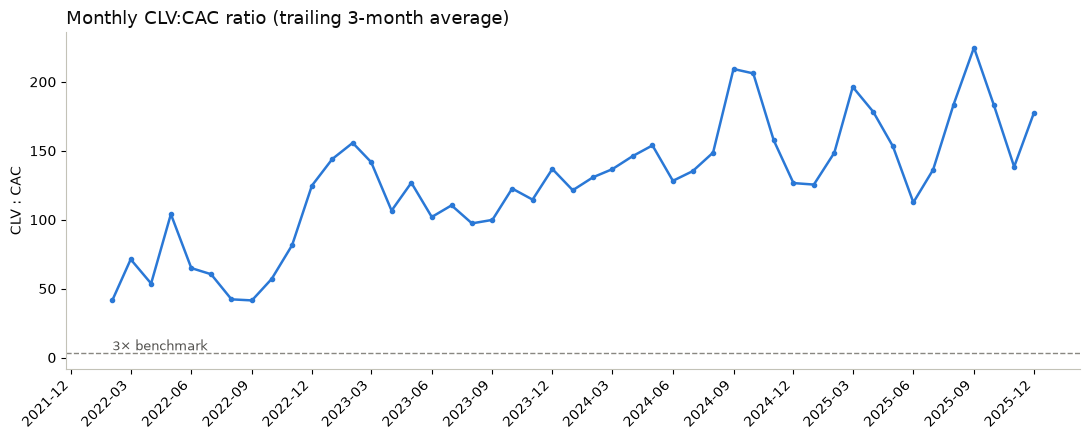

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.5))

ax.plot(monthly_clv_cac["month_date"], monthly_clv_cac["clv_cac_ratio_3mo"],
        color="#2a78d6", linewidth=1.8, marker="o", markersize=3)
ax.axhline(3, color="#898781", linewidth=1, linestyle="--")
ax.text(monthly_clv_cac["month_date"].iloc[0], 3.1, "3× benchmark",
        fontsize=9, color="#52514e", va="bottom")

ax.set_title("Monthly CLV:CAC ratio (trailing 3-month average)", fontsize=13, color="#0b0b0b", loc="left")
ax.set_ylabel("CLV : CAC")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.spines[["bottom", "left"]].set_color("#c3c2b7")
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()
plt.show()